# Intro to Computational Science
# Assignment 2
Timothy Böhm - 17068061

Lydia 

# Problem 1

Implementing of Gillespies Direct Method Algorithm

There are 6 events:
 - Birth
 - Infection
 - Recovery
 - Susceptible death
 - Infected death
 - Recovered death

 Drawing of these events is of exponential time of the sum of their rates.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def gillespie_sir(y, beta, gamma, mu, t_max, seed=None):
    rng = np.random.default_rng(seed)

    S, I, R = y
    t = 0.0

    times = [t]
    S_values = [S]
    I_values = [I]
    R_values = [R]

    while t < t_max:
        N = S + I + R

        if N == 0:
            break

        # Rates of the six possible events
        rates = np.array([
            mu * N,           # Birth
            beta * S * I / N, # Infection
            gamma * I,        # Recovery
            mu * S,           # Susceptible death
            mu * I,           # Infected death
            mu * R            # Recovered death
        ])

        total_rate = np.sum(rates)

        if total_rate == 0:
            break

        # Time until the next event
        dt = rng.exponential(1 / total_rate)

        if t + dt > t_max:
            break

        t += dt

        # Choose which event occurs
        event = rng.choice(len(rates), p=rates / total_rate)

        if event == 0:
            S += 1
        elif event == 1:
            S -= 1
            I += 1
        elif event == 2:
            I -= 1
            R += 1
        elif event == 3:
            S -= 1
        elif event == 4:
            I -= 1
        elif event == 5:
            R -= 1

        # Record the updated state
        times.append(t)
        S_values.append(S)
        I_values.append(I)
        R_values.append(R)

    return [np.array(times), np.array(S_values), np.array(I_values), np.array(R_values)]

In [3]:
from scipy.integrate import odeint
import numpy as np
import matplotlib.pyplot as plt

def sir_demography(y, t, beta, gamma, mu):
    S, I, R = y
    N = S + I + R

    dSdt = mu*N - beta*S*I/N - mu*S
    dIdt = beta*S*I/N - gamma*I - mu*I
    dRdt = gamma*I - mu*R

    return [dSdt, dIdt, dRdt]

In [4]:
# Initial conditions
S0 = 990
I0 = 10
R0 = 0

# Parameters
beta = 0.3
gamma = 0.1
mu = 0.01
t_max = 200

# Deterministic SIR
t = np.linspace(0, t_max, 2000)

sol = odeint(
    sir_demography,
    [S0, I0, R0],
    t,
    args=(beta, gamma, mu)
)

S_det, I_det, R_det = sol.T

# Stochastic SIR using Gillespie
solution = gillespie_sir(
    [S0, I0, R0],
    beta, gamma, mu,
    t_max,
    seed=42
)
t_stoch, S_stoch, I_stoch, R_stoch = solution

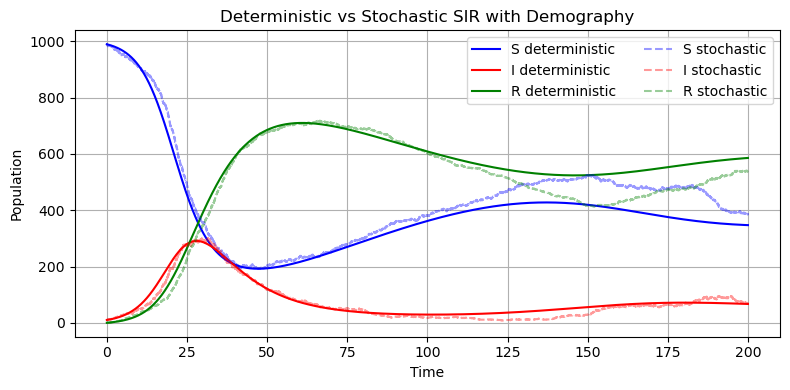

In [9]:
plt.figure(figsize=(8, 4))

# Deterministic model
plt.plot(t, S_det, color="blue", label="S deterministic")
plt.plot(t, I_det, color="red", label="I deterministic")
plt.plot(t, R_det, color="green", label="R deterministic")

# Stochastic model
plt.step(t_stoch, S_stoch, where="post",
         color="blue", alpha=0.4, linestyle="--",
         label="S stochastic")

plt.step(t_stoch, I_stoch, where="post",
         color="red", alpha=0.4, linestyle="--",
         label="I stochastic")

plt.step(t_stoch, R_stoch, where="post",
         color="green", alpha=0.4, linestyle="--",
         label="R stochastic")

plt.xlabel("Time")
plt.ylabel("Population")
plt.title("Deterministic vs Stochastic SIR with Demography")

plt.legend(ncol=2)
plt.grid()
plt.tight_layout()
plt.show()

Problem 2: Spatial Models - Networks 


Erdos Renyi graph specifies number of nodes and $p$ probability that any pair of nodes is connected. $\bar{k} = p(n - 1)$. 

Watts-Strogatz graph specifies number of nodes and each node connects to approximately $k$ neigbours, each edge has a rewiring probabilty of $p$. 

Barabasi-Albert specifies number of nodes. Every node that enters the network creates $m$ edges to existing nodes. $\bar{k} = 2m$. 


In [6]:
import networkx as nx
import ndlib.models.epidemics as ep
import ndlib.models.ModelConfig as mc
import numpy as np 
import matplotlib.pyplot as plt

#number of nodes
n = 374 

#number of runs 
runs = 100 

#making lists that store network results 
mean_degree = {'BA': [], 'WS': [], 'ER': []}
mean_clustering = {'BA': [], 'WS': [], 'ER': []}
mean_betweenness = {'BA': [], 'WS': [], 'ER': []}
degree_distribution = {'BA': [], 'WS': [], 'ER': []}

for i in range(runs):
    #defining networks with similar properties (374 nodes and a degree between 6 and 7)
    g_ba = nx.barabasi_albert_graph(n = n, m = 3, seed = i)
    g_ws = nx.watts_strogatz_graph(n = n, k = 6, p = 0.1, seed = i)
    g_er = nx.erdos_renyi_graph(n = n, p = 0.018, seed = i)

    network = {'BA': g_ba, 'WS': g_ws, 'ER': g_er}
    
    #get statistics from each network 
    for name, g in network.items():
        degrees = [degree for node, degree in g.degree]
        mean_degree[name].append(np.mean(degrees))
        mean_clustering[name].append(nx.average_clustering(g))
        degree_distribution[name].extend(degrees)
        betweenness = nx.betweenness_centrality(g)
        betweenness_values = list(betweenness.values())
        mean_betweenness[name].append(np.mean(betweenness_values))

#plotting
#mean degree 
network_names = ['BA', 'WS', 'ER']

plt.boxplot([mean_degree['BA'], mean_degree['WS'], mean_degree['ER']],tick_labels=network_names)
plt.title('Mean degree')
plt.ylabel(r'Mean degree $\bar{k}$')
plt.show()


#mean clustering 
plt.boxplot([mean_clustering['BA'], mean_clustering['WS'], mean_clustering['ER']], tick_labels=network_names)
plt.title('Mean clustering')
plt.ylabel('Clustering coefficient')
plt.show()

#mean betweenness
plt.boxplot([mean_betweenness['BA'], mean_betweenness['WS'], mean_betweenness['ER']], tick_labels=network_names)
plt.title('Mean betweenness centrality')
plt.ylabel('Mean betweenness centrality')
plt.show()

#degree distribution BA
plt.hist(degree_distribution['BA'], bins=30, density=True)
plt.xlabel('Degree')
plt.ylabel('Density')
plt.title('Degree distribution: Barabasi-Albert')
plt.show()

#degree distribution WS
plt.hist(degree_distribution['WS'], bins=30, density=True)
plt.xlabel('Degree')
plt.ylabel('Density')
plt.title('Degree distribution: Watts-Strogatz')
plt.show()

#degree distribution ER
plt.hist(degree_distribution['ER'], bins=30, density=True)
plt.xlabel('Degree')
plt.ylabel('Density')
plt.title('Degree distribution: Erdos-Renyi')
plt.show()

ModuleNotFoundError: No module named 'ndlib'

Simulating SIR spread on networks 

Simulating with varying fraction of initial infected, which nodes are initially infected and $\beta$

In [ ]:
import ndlib.models.ModelConfig as mc

#generating different network types with similar properties 
g_ba = nx.barabasi_albert_graph(n = n, m = 3, seed = 0)
g_ws = nx.watts_strogatz_graph(n = n, k = 6, p = 0.1, seed = 0)
g_er = nx.erdos_renyi_graph(n = n, p = 0.018, seed = 0)
network = {'BA': g_ba, 'WS': g_ws, 'ER': g_er}

#function that runs one SIR simulation 
def run_sir(g, beta, gamma, iterations = 100, fraction_infected = 0.05, infected_nodes = None, seed = None):

    #specify model 
    model = ep.SIRModel(g, seed=seed)

    #model configuration 
    config = mc.Configuration()
    config.add_model_parameter('beta', beta)
    config.add_model_parameter('gamma', gamma)
    config.add_model_parameter('fraction_infected', fraction_infected)
    if infected_nodes is not None:
        config.add_model_initial_configuration('Infected', infected_nodes)
    model.set_initial_status(config)

    # Run simulation
    output = model.iteration_bunch(iterations)

    #collecting states of each node 
    S = [step['node_count'][0] for step in output]
    I = [step['node_count'][1] for step in output]
    R = [step['node_count'][2] for step in output]

    return np.array(S), np.array(I), np.array(R)

#function that repeats stochastic SIR model  
def repeat_sir(g, beta, gamma, runs = nruns, fraction_infected = 0.05, infected_nodes=None):
    S_runs = []
    I_runs = []
    R_runs = []

    for i in range(runs):

        S, I, R = run_sir(g, beta, gamma, fraction_infected = fraction_infected, infected_nodes = infected_nodes, seed = i)
        S_runs.append(S)
        I_runs.append(I)
        R_runs.append(R)
    return (np.array(S_runs), np.array(I_runs), np.array(R_runs))



Varying fractions initially infected in different network types

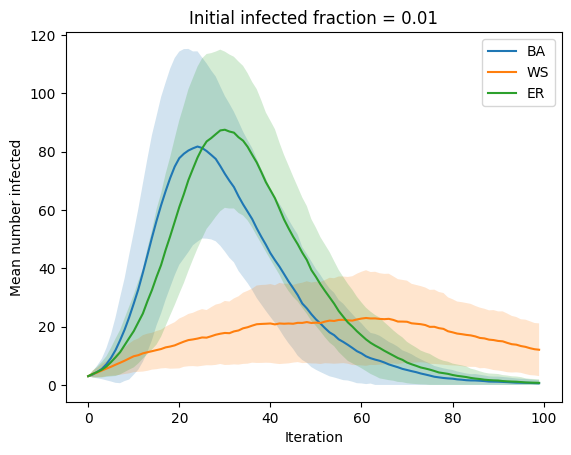

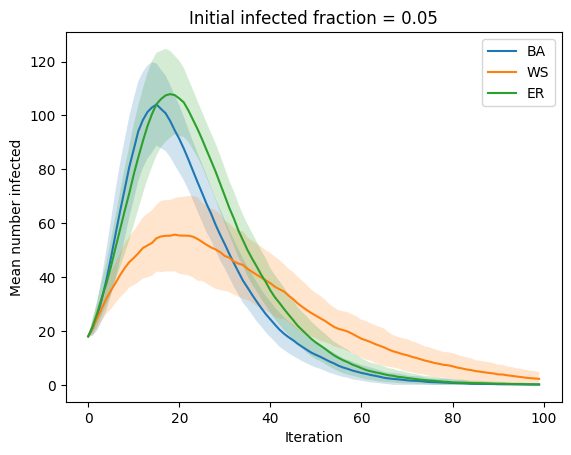

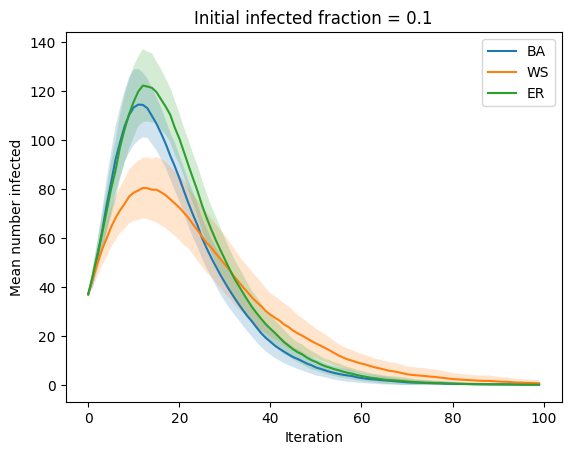

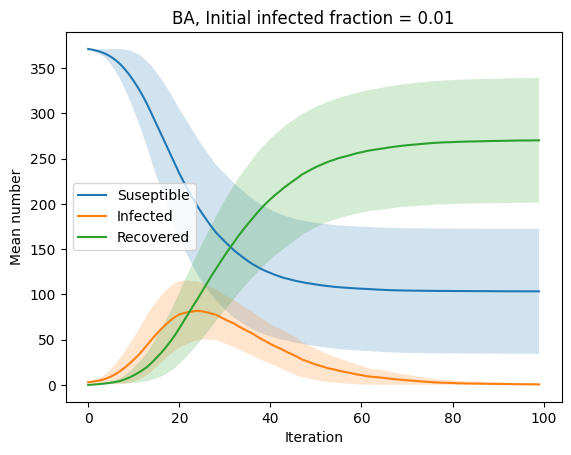

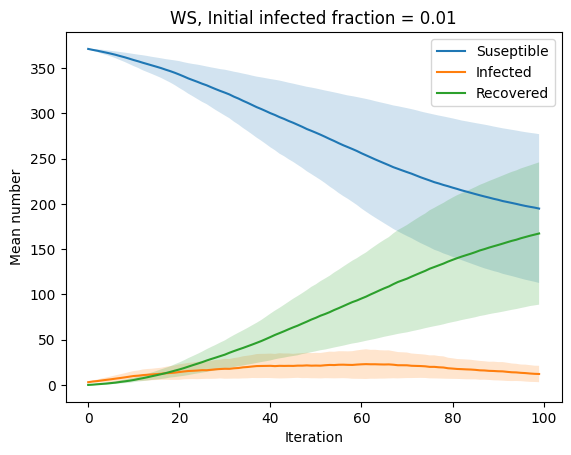

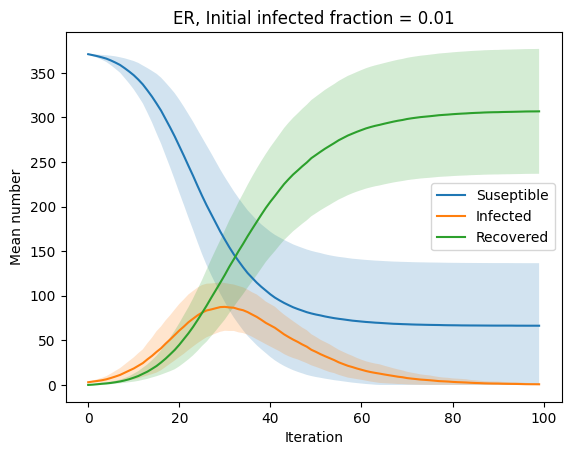

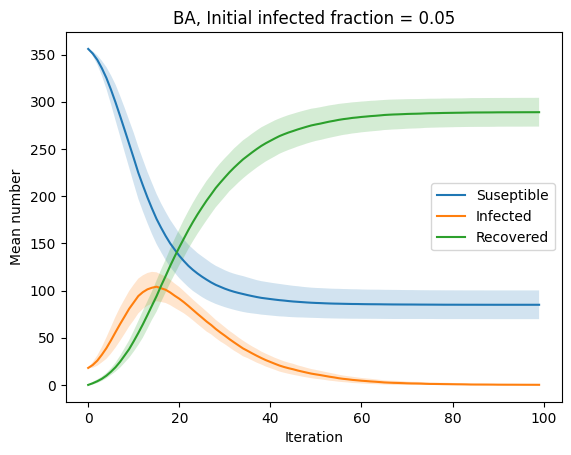

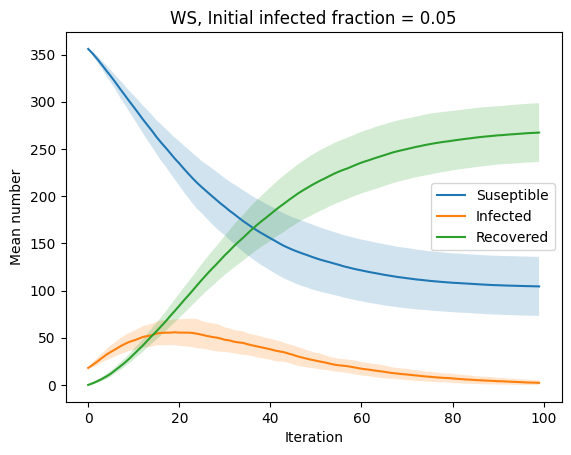

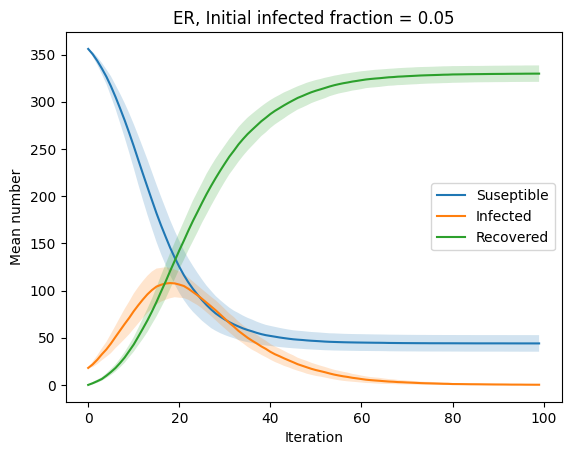

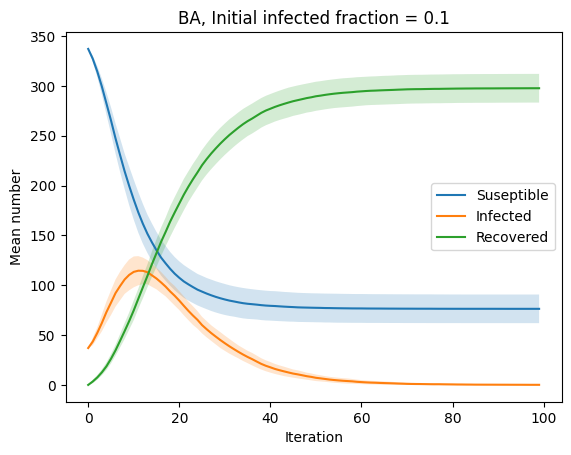

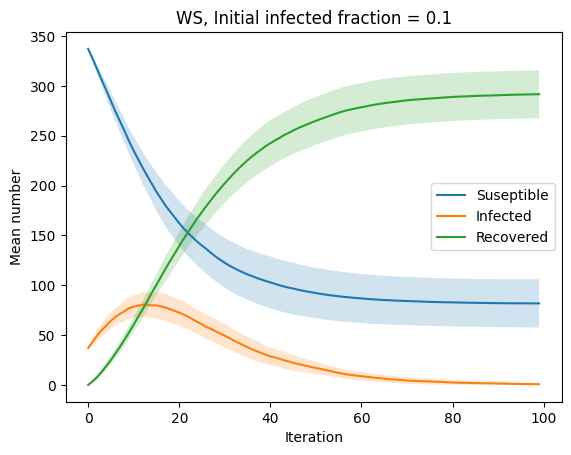

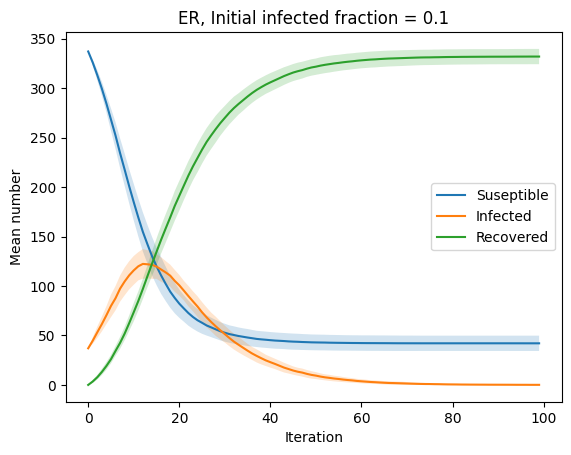

In [ ]:
initial_infected_fractions = [0.01, 0.05, 0.10]
beta = 0.05
gamma = 0.1
nruns = 100
results_changing_fractions = {}

for fraction in initial_infected_fractions:
    results_changing_fractions[fraction] = {}
    for name, g in network.items():
        S_runs, I_runs, R_runs = repeat_sir(g, beta, gamma, runs = nruns, fraction_infected = fraction)
        results_changing_fractions[fraction][name] = {'S' : S_runs, 'I' : I_runs, 'R' : R_runs}

#plotting mean number infected  
for fraction in initial_infected_fractions:
    for name in network:
        I_runs = results_changing_fractions[fraction][name]['I']
        mean_I = np.mean(I_runs, axis=0)
        std_I = np.std(I_runs, axis=0)
        plt.plot(mean_I, label = name)
        plt.fill_between(np.arange(len(mean_I)), np.maximum(mean_I - std_I, 0), mean_I + std_I, alpha=0.2)
    plt.xlabel('Iteration')
    plt.ylabel('Mean number infected')
    plt.title(f'Initial infected fraction = {fraction}')
    plt.legend()
    plt.show()

#plotting SIR
for fraction in initial_infected_fractions:
    for name in network:
        S_runs = results_changing_fractions[fraction][name]['S']
        I_runs = results_changing_fractions[fraction][name]['I']
        R_runs = results_changing_fractions[fraction][name]['R']
        mean_S = np.mean(S_runs, axis=0)
        mean_I = np.mean(I_runs, axis=0)
        mean_R = np.mean(R_runs, axis=0)
        std_S = np.std(S_runs, axis=0)
        std_I = np.std(I_runs, axis=0)
        std_R = np.std(R_runs, axis=0)
        plt.plot(mean_S, label = 'Suseptible')
        plt.fill_between(np.arange(len(mean_S)), np.maximum(mean_S - std_S, 0), mean_S + std_S, alpha=0.2)
        plt.plot(mean_I, label = 'Infected')
        plt.fill_between(np.arange(len(mean_I)), np.maximum(mean_I - std_I, 0), mean_I + std_I, alpha=0.2)
        plt.plot(mean_R, label = 'Recovered')
        plt.fill_between(np.arange(len(mean_R)), np.maximum(mean_R - std_R, 0), mean_R + std_R, alpha=0.2)
        plt.xlabel('Iteration')
        plt.ylabel('Mean number')
        plt.title(f'{name}, Initial infected fraction = {fraction}')
        plt.legend()
        plt.show()


Simulating with varying which nodes are infected

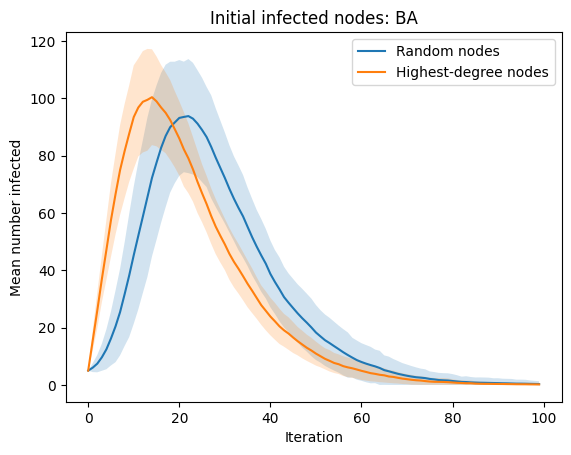

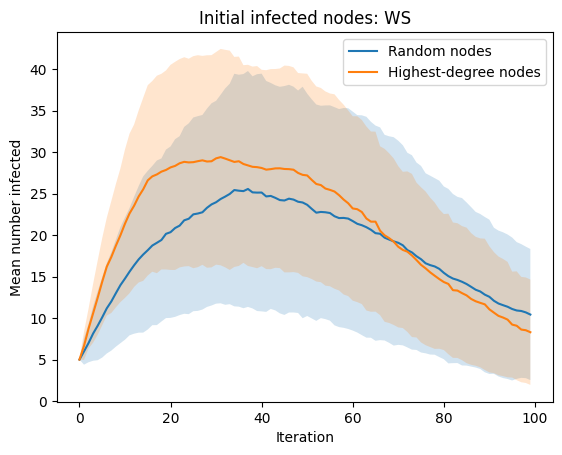

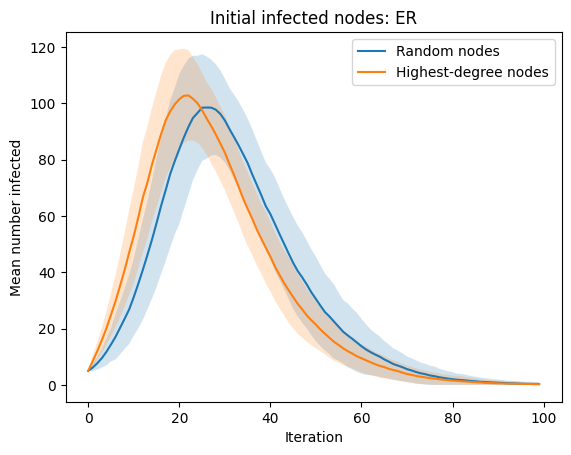

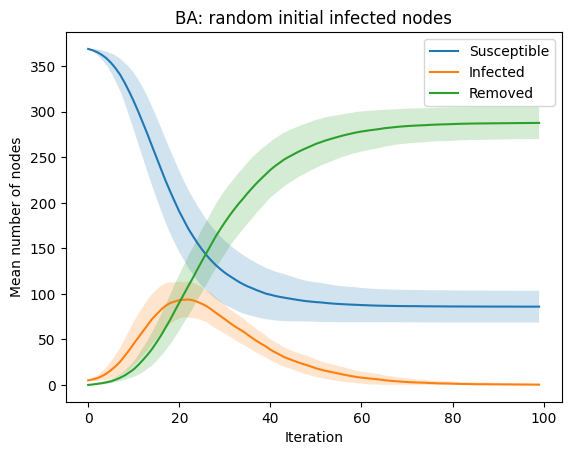

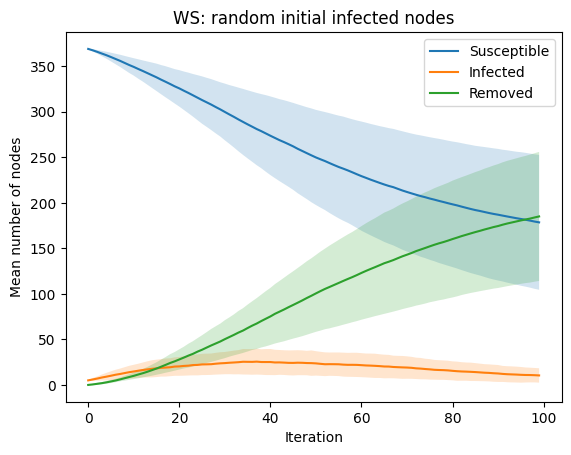

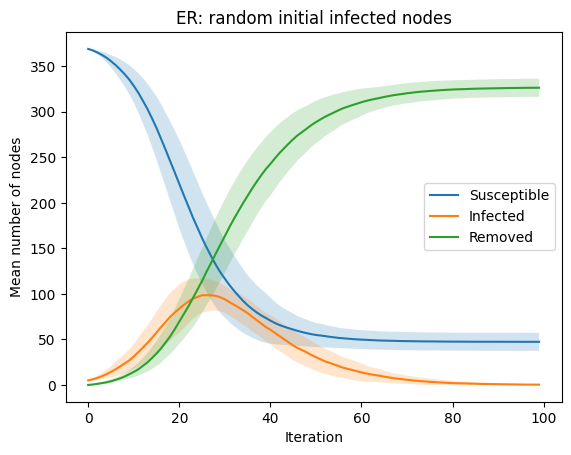

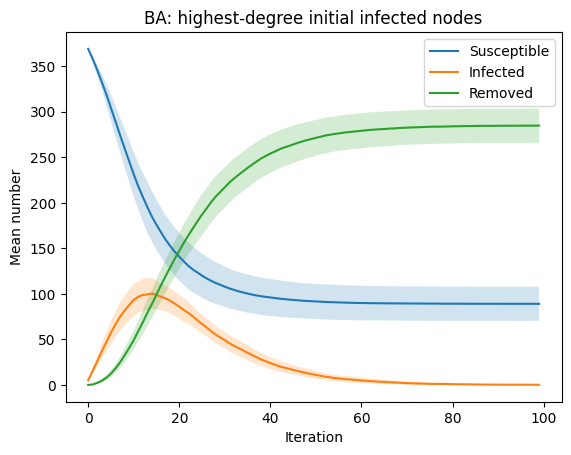

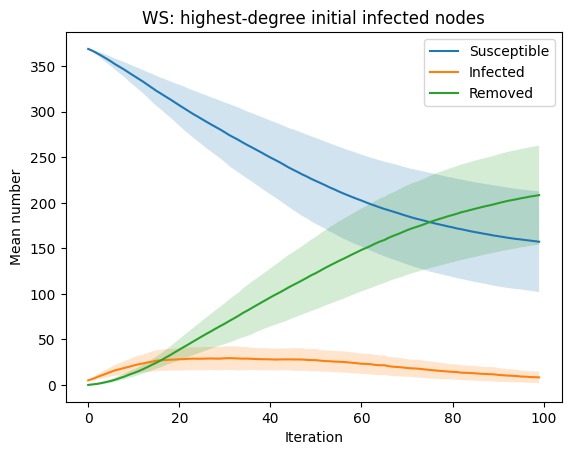

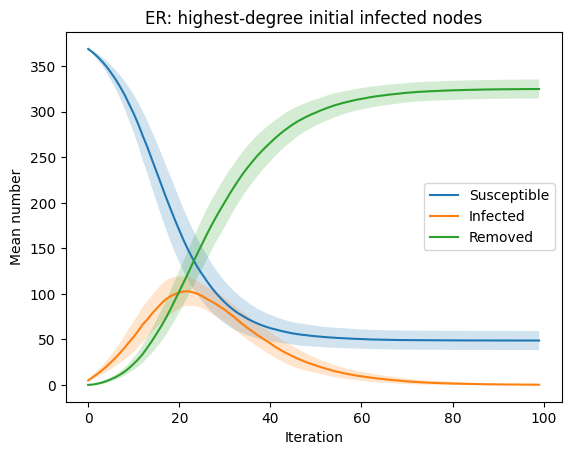

In [ ]:
beta = 0.05
gamma = 0.1
nruns = 100
number_infected = 5
results_nodes = {}

for name, g in network.items():

    results_nodes[name] = {'random': {'S' : [], 'I' : [], 'R' : []}, 'high_degree': {'S' : [], 'I': [], 'R': []}}

    #getting the highest degree nodes
    highest_degree = sorted(g.degree, key = lambda x: x[1], reverse = True)[:number_infected]
    highest_degree_nodes = [node for node, degree in highest_degree]

    for i in range(nruns):
        #generating random nodes 
        rng = np.random.default_rng(i)
        random_nodes = rng.choice(list(g.nodes()), size = number_infected, replace = False).tolist()

        S, I, R = run_sir(g, beta, gamma, infected_nodes = random_nodes, seed = i)
        results_nodes[name]['random']['S'].append(S)
        results_nodes[name]['random']['I'].append(I)
        results_nodes[name]['random']['R'].append(R)

        S, I, R = run_sir(g, beta, gamma, infected_nodes = highest_degree_nodes, seed = i)
        results_nodes[name]['high_degree']['S'].append(S)
        results_nodes[name]['high_degree']['I'].append(I)
        results_nodes[name]['high_degree']['R'].append(R)

#plotting mean infected 
for name in network:
    random_runs = np.array(results_nodes[name]['random']['I'])
    high_degree_runs = np.array(results_nodes[name]['high_degree']['I'])

    mean_random = np.mean(random_runs, axis = 0)
    std_random = np.std(random_runs, axis = 0)
    mean_high_degree = np.mean(high_degree_runs, axis=0)
    std_high_degree = np.std(high_degree_runs, axis=0)
    plt.plot(mean_random, label='Random nodes')
    plt.fill_between(np.arange(len(mean_random)), np.maximum(mean_random - std_random, 0), mean_random + std_random, alpha=0.2)
    plt.plot(mean_high_degree, label='Highest-degree nodes')
    plt.fill_between(np.arange(len(mean_high_degree)), np.maximum(mean_high_degree - std_high_degree, 0), mean_high_degree + std_high_degree, alpha=0.2)
    plt.xlabel('Iteration')
    plt.ylabel('Mean number infected')
    plt.title(f'Initial infected nodes: {name}')
    plt.legend()
    plt.show()

#plotting SIR random nodes 
for name in network:
    S_runs = np.array(results_nodes[name]['random']['S'])
    I_runs = np.array(results_nodes[name]['random']['I'])
    R_runs = np.array(results_nodes[name]['random']['R'])


    mean_S = np.mean(S_runs, axis=0)
    mean_I = np.mean(I_runs, axis=0)
    mean_R = np.mean(R_runs, axis=0)
    std_S = np.std(S_runs, axis=0)
    std_I = np.std(I_runs, axis=0)
    std_R = np.std(R_runs, axis=0)

    plt.plot(mean_S, label='Susceptible')
    plt.fill_between(np.arange(len(mean_S)), np.maximum(mean_S - std_S, 0), mean_S + std_S, alpha=0.2)
    plt.plot(mean_I, label='Infected')
    plt.fill_between(np.arange(len(mean_I)), np.maximum(mean_I - std_I, 0), mean_I + std_I, alpha=0.2)
    plt.plot(mean_R, label='Removed')
    plt.fill_between(np.arange(len(mean_R)), np.maximum(mean_R - std_R, 0), mean_R + std_R, alpha=0.2)
    plt.xlabel('Iteration')
    plt.ylabel('Mean number of nodes')
    plt.title(f'{name}: random initial infected nodes')
    plt.legend()
    plt.show()

#plot SIR high degree nodes 
for name in network:
    S_runs = np.array(results_nodes[name]['high_degree']['S'])
    I_runs = np.array(results_nodes[name]['high_degree']['I'])
    R_runs = np.array(results_nodes[name]['high_degree']['R'])


    mean_S = np.mean(S_runs, axis=0)
    mean_I = np.mean(I_runs, axis=0)
    mean_R = np.mean(R_runs, axis=0)
    std_S = np.std(S_runs, axis=0)
    std_I = np.std(I_runs, axis=0)
    std_R = np.std(R_runs, axis=0)

    plt.plot(mean_S, label='Susceptible')
    plt.fill_between(np.arange(len(mean_S)), np.maximum(mean_S - std_S, 0), mean_S + std_S, alpha=0.2)
    plt.plot(mean_I, label='Infected')
    plt.fill_between(np.arange(len(mean_I)), np.maximum(mean_I - std_I, 0), mean_I + std_I, alpha=0.2)
    plt.plot(mean_R, label='Removed')
    plt.fill_between(np.arange(len(mean_R)), np.maximum(mean_R - std_R, 0), mean_R + std_R, alpha=0.2)
    plt.xlabel('Iteration')
    plt.ylabel('Mean number')
    plt.title(f'{name}: highest-degree initial infected nodes')
    plt.legend()
    plt.show()

Simulating with varying $\beta$

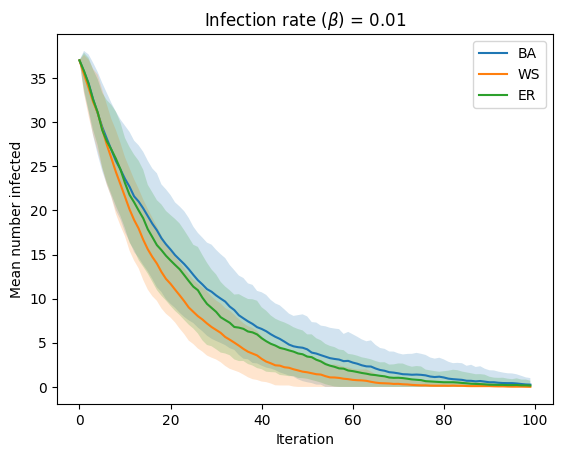

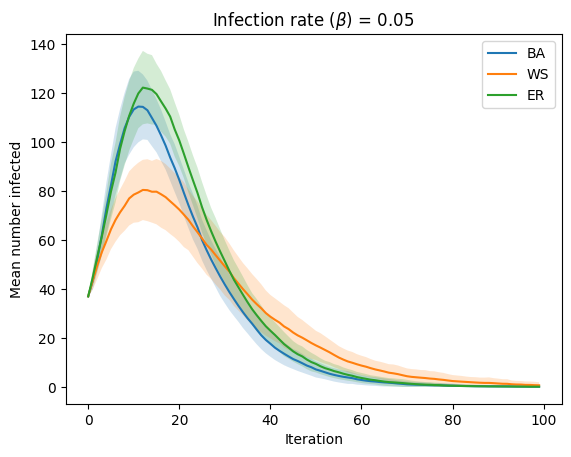

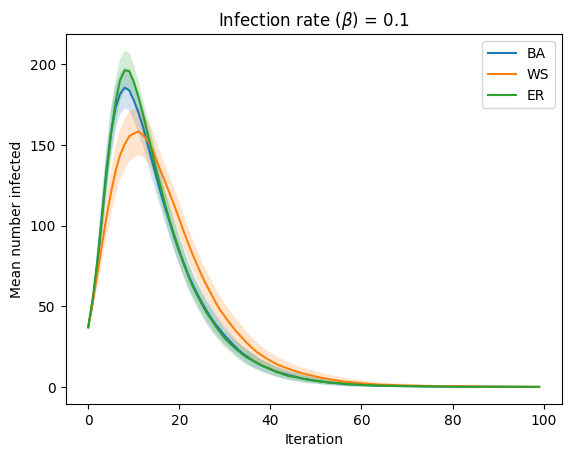

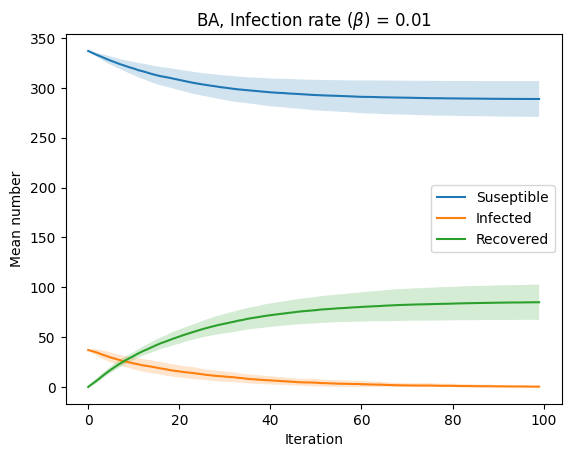

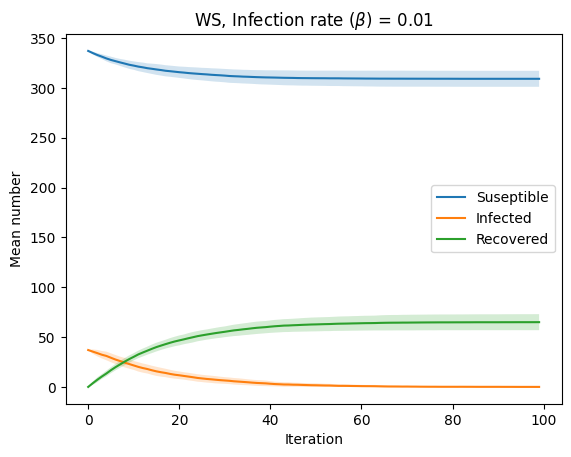

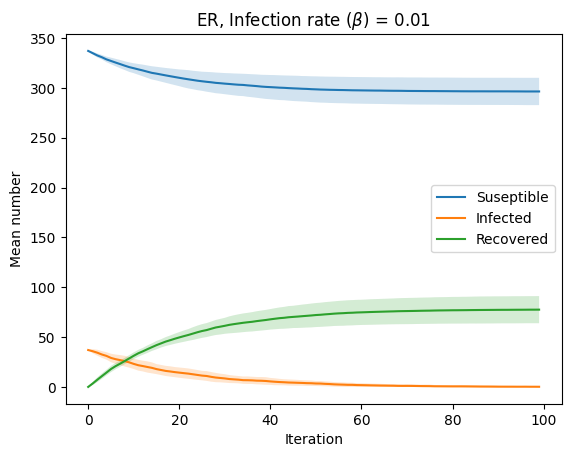

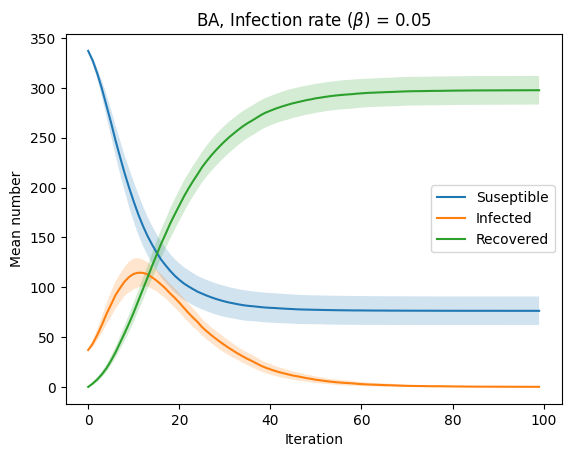

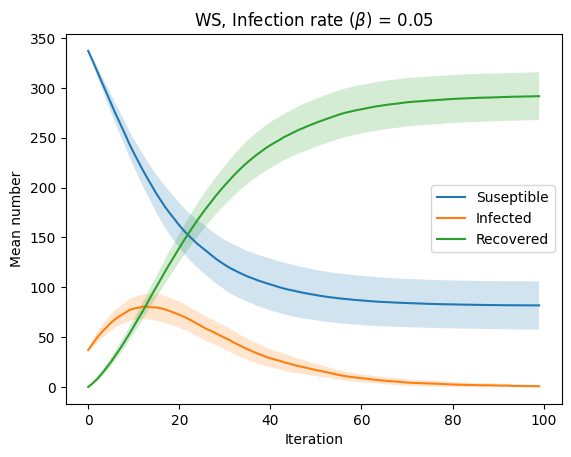

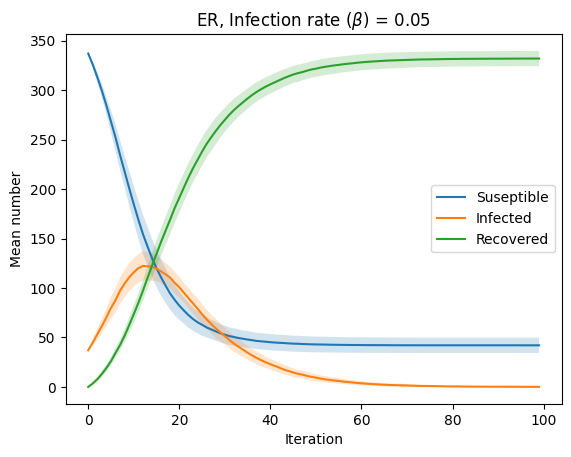

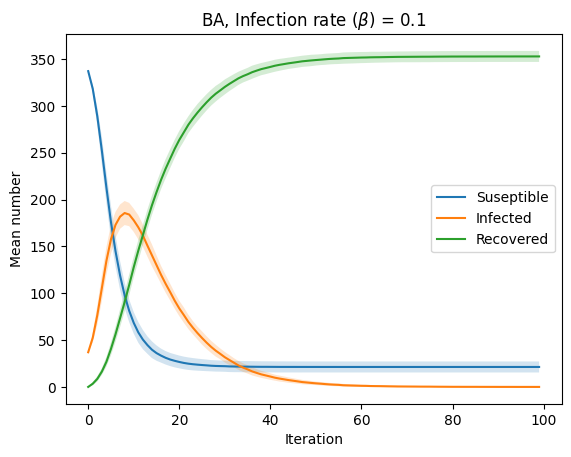

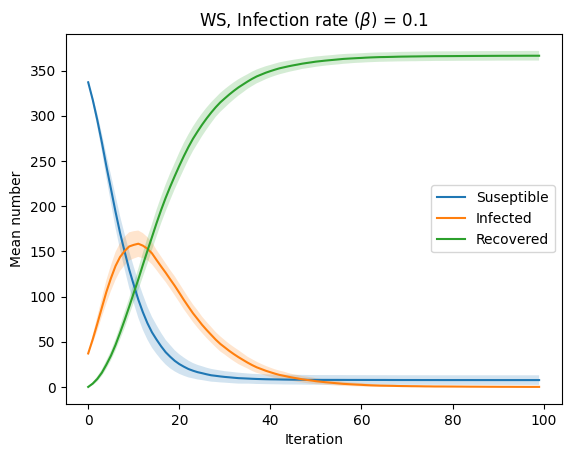

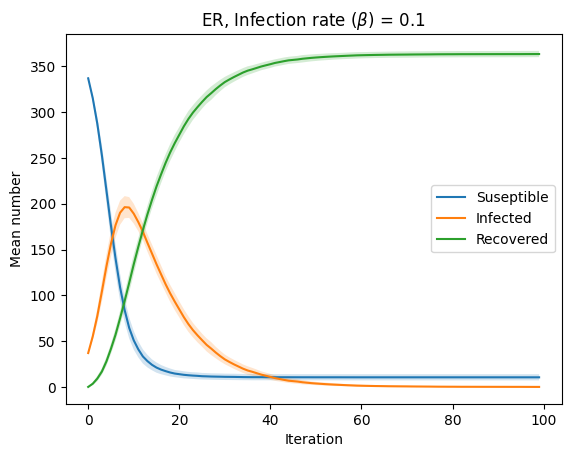

In [ ]:
changing_beta= [0.01, 0.05, 0.10]
infected_fraction = 0.1
gamma = 0.1
nruns = 100
results_changing_beta = {}

for beta in changing_beta:
    results_changing_beta[beta] = {}
    for name, g in network.items():
        S_runs, I_runs, R_runs = repeat_sir(g, beta, gamma, runs = nruns, fraction_infected = infected_fraction)
        results_changing_beta[beta][name] = {'S' : S_runs, 'I' : I_runs, 'R' : R_runs}

#plotting mean number infected  
for beta in changing_beta:
    for name in network:
        I_runs = results_changing_beta[beta][name]['I']
        mean_I = np.mean(I_runs, axis=0)
        std_I = np.std(I_runs, axis=0)
        plt.plot(mean_I, label = name)
        plt.fill_between(np.arange(len(mean_I)), np.maximum(mean_I - std_I, 0), mean_I + std_I, alpha=0.2)
    plt.xlabel('Iteration')
    plt.ylabel('Mean number infected')
    plt.title(rf'Infection rate ($\beta$) = {beta}')
    plt.legend()
    plt.show()

#plotting SIR
for beta in changing_beta:
    for name in network:
        S_runs = results_changing_beta[beta][name]['S']
        I_runs = results_changing_beta[beta][name]['I']
        R_runs = results_changing_beta[beta][name]['R']
        mean_S = np.mean(S_runs, axis=0)
        mean_I = np.mean(I_runs, axis=0)
        mean_R = np.mean(R_runs, axis=0)
        std_S = np.std(S_runs, axis=0)
        std_I = np.std(I_runs, axis=0)
        std_R = np.std(R_runs, axis=0)
        plt.plot(mean_S, label = 'Suseptible')
        plt.fill_between(np.arange(len(mean_S)), np.maximum(mean_S - std_S, 0), mean_S + std_S, alpha=0.2)
        plt.plot(mean_I, label = 'Infected')
        plt.fill_between(np.arange(len(mean_I)), np.maximum(mean_I - std_I, 0), mean_I + std_I, alpha=0.2,)
        plt.plot(mean_R, label = 'Recovered')
        plt.fill_between(np.arange(len(mean_R)), np.maximum(mean_R - std_R, 0), mean_R + std_R, alpha=0.2)
        plt.xlabel('Iteration')
        plt.ylabel('Mean number')
        plt.title(rf'{name}, Infection rate ($\beta$) = {beta}')
        plt.legend()
        plt.show()
